# 05 — Model Monitoring & TensorBoard

**Lab 2 — Group 4 | CIFAR-10**

Bổ sung cho bước 6: theo dõi train/validation loss, accuracy, generalization gap, learning rate, thời gian mỗi epoch và bộ nhớ CUDA nếu có. Notebook 04 ghi log trong khi huấn luyện; notebook này đọc kết quả, không train lại. Chế độ review chỉ sử dụng số đo đã lưu.

Cấu hình `MODE` và `RUN_ID` tại cell code đầu tiên; khi chạy mới cần trùng với notebook 04.

In [1]:
from pathlib import Path
import sys, os
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs').is_dir() and (p/'src').is_dir()), None)
assert ROOT is not None, 'Hãy mở notebook trong thư mục dự án đã giải nén.'
sys.path.insert(0, str(ROOT))
# Cấu hình trực tiếp trong notebook (không cần file cấu hình riêng).
MODE = "review"  # review: kết quả gốc; full: chạy thực tế
RUN_ID = "run_01"  # notebook 04–06 phải dùng cùng tên khi chạy full
DEVICE_OVERRIDE = "auto"  # auto / cpu / cuda
CPU_THREADS = 1
LIVE = MODE == "full"
assert MODE in ("review", "full")
DOWNLOAD = True
import io, json, random, hashlib, time, gc
from pathlib import Path
from datetime import datetime
from uuid import uuid4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

DATA_DIR = ROOT / 'data'
SESSION_DIR = ROOT / 'outputs' / 'notebook_runs' / RUN_ID
FIG_DIR = SESSION_DIR / 'figures'
SAVE_FIGS = LIVE

def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

random.seed(SEED)
np.random.seed(SEED)
if LIVE:
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import DataLoader, Subset, random_split
    from torchvision import transforms, models
    from PIL import Image
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    from torch.utils.tensorboard import SummaryWriter
    import torch.nn.functional as F

    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

    set_seed(SEED)
    DEVICE = torch.device(("cuda" if torch.cuda.is_available() else "cpu")
                          if DEVICE_OVERRIDE == "auto" else DEVICE_OVERRIDE)
    if DEVICE.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA không khả dụng. Chọn CPU hoặc sửa môi trường.")
    if DEVICE.type == "cpu":
        torch.set_num_threads(CPU_THREADS)
    print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
    print("Device:", DEVICE)
    print("Data:", DATA_DIR, "| Output mới:", SESSION_DIR)
else:
    print("Review: không cần import PyTorch, không tạo file training.")

Review: không cần import PyTorch, không tạo file training.


## 6.4. TensorBoard — theo dõi trực tiếp trong lúc training
Chạy lệnh dưới đây trong terminal riêng **trước hoặc trong khi chạy notebook 04** ở chế độ full. Mở `http://localhost:6006` → Scalars. Các nhóm tag: `Loss/`, `Accuracy/`, `Batch/`, `Monitoring/`. Batch được ghi ở batch đầu, mỗi 50 batch và batch cuối. Reload để xem log mới. Review không có event file gốc; hình dưới đây là minh chứng trong báo cáo, không phải log mới.

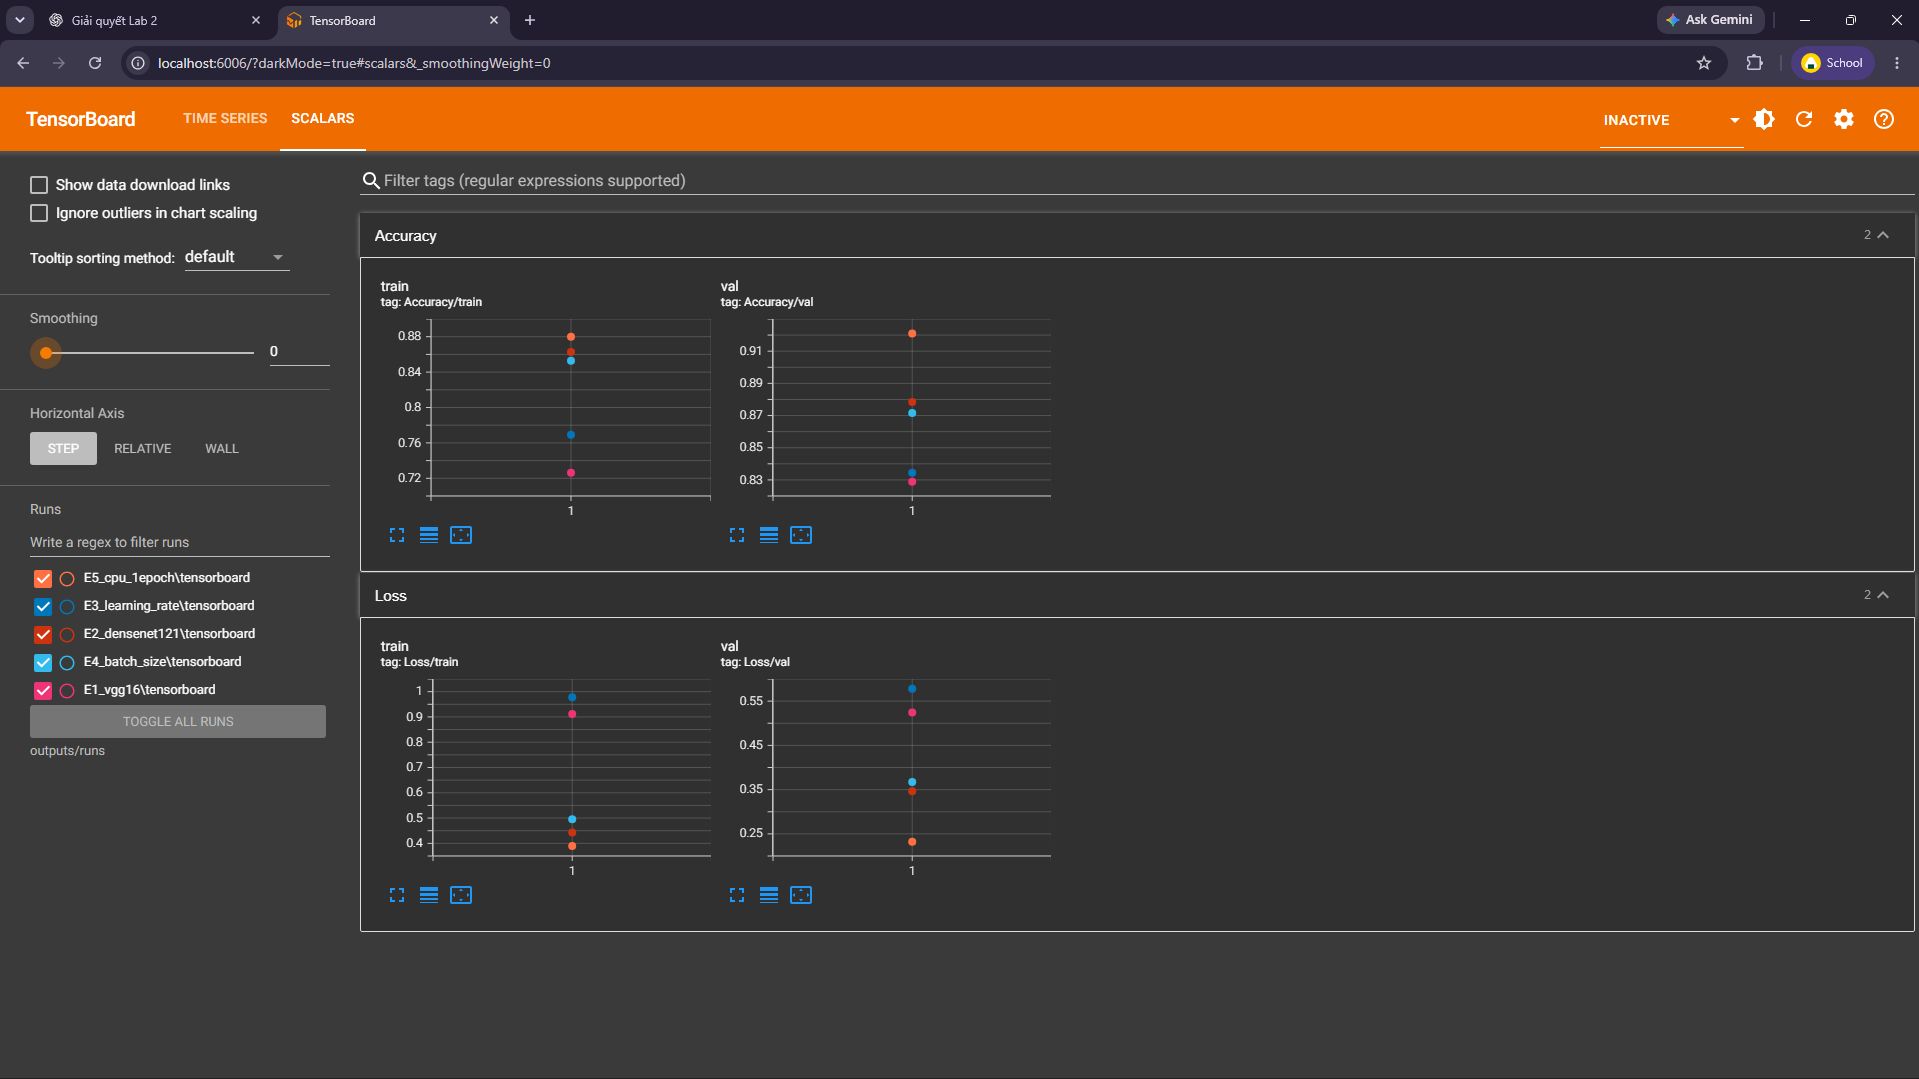

Review: không có event files gốc để mở TensorBoard trực tiếp.


In [2]:
run_root = SESSION_DIR/'training' if LIVE else ROOT/'outputs'
if LIVE:
    print(f'tensorboard --logdir "{run_root}" --port 6006')
    print('http://localhost:6006')
    print('Số event files hiện có:', len(list(run_root.rglob('events.out.tfevents.*'))))
else:
    from IPython.display import Image as DisplayImage
    image_path = ROOT/'reports/figures/tensorboard_comparison.png'
    if image_path.exists():
        display(DisplayImage(filename=str(image_path)))
    print('Review: không có event files gốc để mở TensorBoard trực tiếp.')

## 6.5. Đọc lịch sử và thông số thực nghiệm
Accuracy là tỷ lệ 0–1 trong CSV; chuyển sang % khi vẽ. Gap accuracy = train accuracy − validation accuracy (điểm phần trăm). Gap loss = validation loss − train loss. Khi training đang chạy có thể Run lại cell đọc log để cập nhật các epoch hoàn thành; không thay đổi checkpoint.

In [3]:
import yaml
run_ids = ['E1_vgg16','E2_densenet121','E3_learning_rate','E4_batch_size','E5_cpu_1epoch']
frames = []
for name in run_ids:
    directory = run_root/name if LIVE else run_root/'runs'/name
    path = directory/'history.csv'
    if not path.is_file():
        print(f'{name}: chưa có history')
        continue
    h = pd.read_csv(path)
    if h.empty:
        continue
    h['experiment'] = name.split('_')[0]
    h['accuracy_gap_pp'] = (h.train_accuracy - h.val_accuracy)*100
    h['loss_gap'] = h.val_loss - h.train_loss
    # LR lịch sử lấy từ config; LR mới lấy trực tiếp từ optimizer đã ghi.
    if 'learning_rate' not in h:
        cfg = json.loads((directory/'config.json').read_text(encoding='utf-8'))
        h['learning_rate'] = cfg['learning_rate']
    frames.append(h)
assert frames, 'Chạy notebook 04 để tạo ít nhất một epoch history.'
monitor = pd.concat(frames,ignore_index=True)
print('Nguồn:', 'log thực nghiệm mới' if LIVE else 'history.csv gốc')
display(monitor)

Nguồn: history.csv gốc


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,experiment,accuracy_gap_pp,loss_gap,learning_rate
0,1,0.911464,0.726156,0.524489,0.8288,E1,-10.264444,-0.386974,0.0010
1,1,0.442884,0.862622,0.346216,0.8784,E2,-1.577778,-0.096668,0.0010
2,1,0.978248,0.769289,0.577797,0.8344,E3,-6.511111,-0.400451,0.0001
3,1,0.494990,0.852800,0.367412,0.8716,E4,-1.880000,-0.127578,0.0010
4,1,0.389262,0.879911,0.232135,0.9210,E5,-4.108889,-0.157127,0.0001


## 6.6. Learning curves và generalization gap
Mỗi đường biểu diễn một thí nghiệm; marker vẫn hiển thị nếu chỉ có một epoch. Loss thấp hơn và accuracy cao hơn trên validation thường là tín hiệu tích cực; không kết luận hội tụ từ một điểm đo.

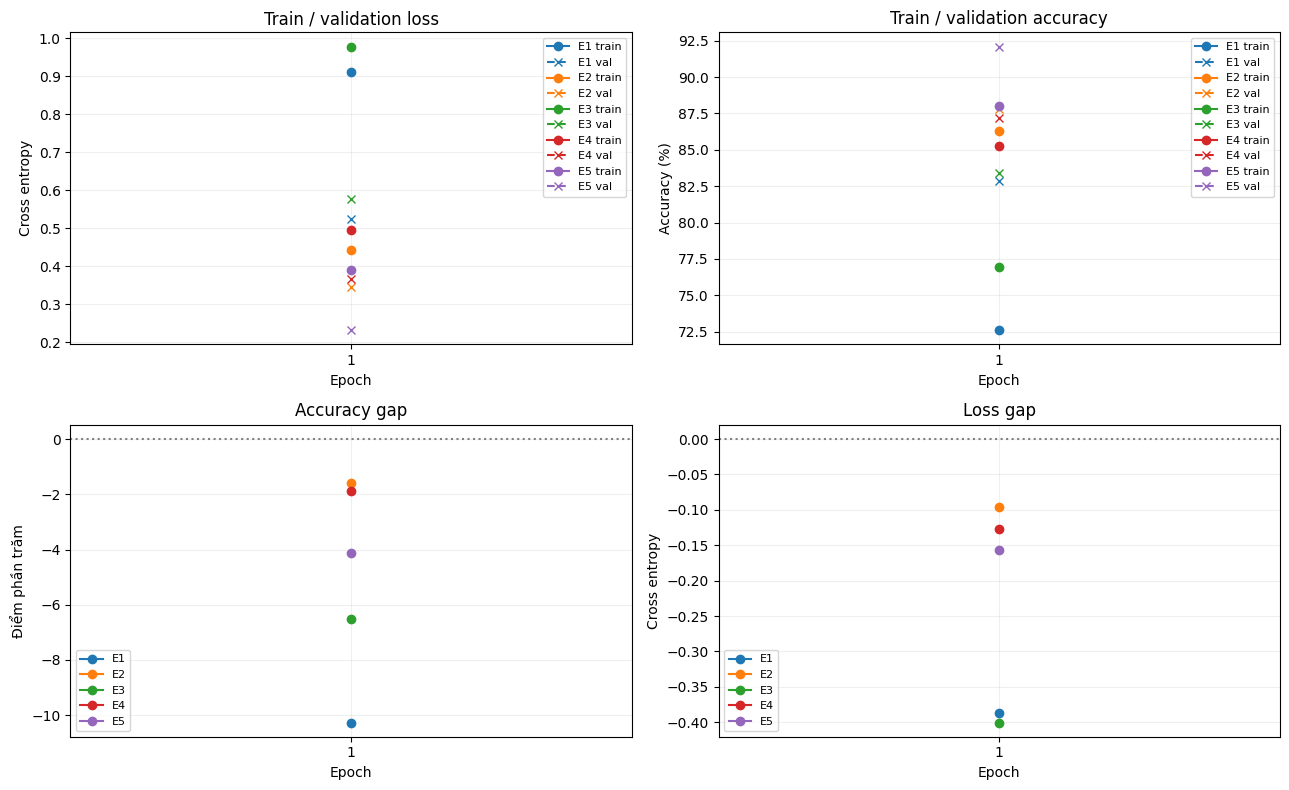

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13,8))
for name, h in monitor.groupby('experiment', sort=False):
    h = h.sort_values('epoch')
    for ax, tr, val, factor in [(axes[0,0],'train_loss','val_loss',1),(axes[0,1],'train_accuracy','val_accuracy',100)]:
        line, = ax.plot(h.epoch,h[tr]*factor,'o-',label=f'{name} train')
        ax.plot(h.epoch,h[val]*factor,'x--',color=line.get_color(),label=f'{name} val')
    axes[1,0].plot(h.epoch,h.accuracy_gap_pp,'o-',label=name)
    axes[1,1].plot(h.epoch,h.loss_gap,'o-',label=name)
for ax, title, ylabel in zip(axes.flat,['Train / validation loss','Train / validation accuracy','Accuracy gap','Loss gap'],['Cross entropy','Accuracy (%)','Điểm phần trăm','Cross entropy']):
    ax.set(title=title,xlabel='Epoch',ylabel=ylabel)
    ax.set_xticks(sorted(monitor.epoch.unique()))
    ax.grid(alpha=.2); ax.legend(fontsize=8)
for ax in axes[1]: ax.axhline(0,color='gray',linestyle=':')
plt.tight_layout(); plt.show()

## 6.7. Learning rate, thời gian và tài nguyên
LR của run gốc lấy từ config (optimizer không có scheduler trong cấu hình gốc). Thời gian toàn run lấy từ bảng summary; lịch sử cũ không có thời gian mỗi epoch hay GPU memory nên không tự tạo dữ liệu. GPU peak memory chỉ có khi chạy CUDA.

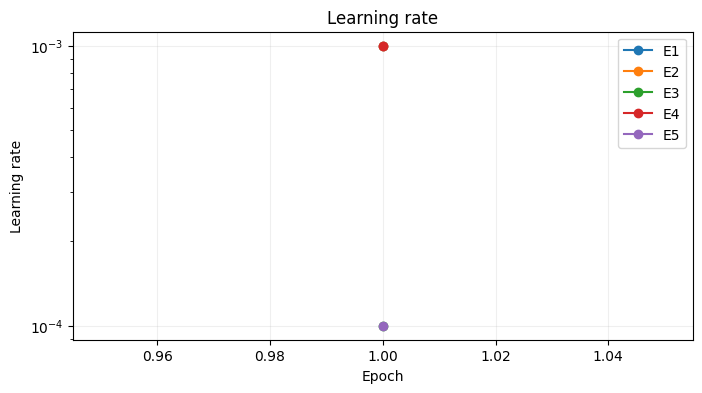

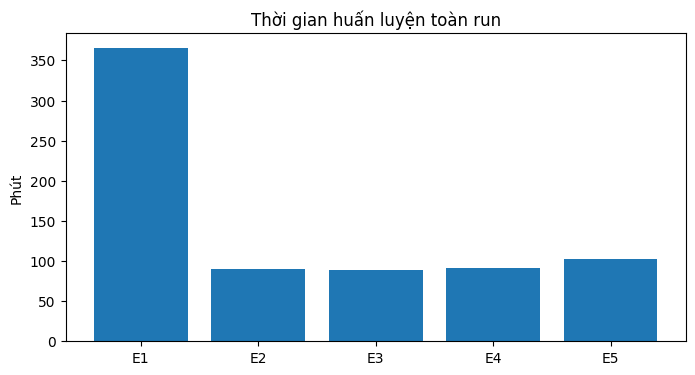

Thời gian mỗi epoch (giây): chưa có số đo.
CUDA peak allocated (MiB): chưa có số đo.


In [5]:
fig, ax = plt.subplots(figsize=(8,4))
for name,h in monitor.groupby('experiment',sort=False):
    ax.plot(h.epoch,h.learning_rate,'o-',label=name)
ax.set(xlabel='Epoch',ylabel='Learning rate',title='Learning rate',yscale='log'); ax.legend(); ax.grid(alpha=.2)
plt.show()
summary_path=run_root/'experiment_summary.csv'
if summary_path.is_file():
    s=pd.read_csv(summary_path)
    plt.figure(figsize=(8,4)); plt.bar(s.experiment_name.str.split('_').str[0],s.training_time_sec/60)
    plt.ylabel('Phút'); plt.title('Thời gian huấn luyện toàn run'); plt.show()
else:
    print('Summary chưa hoàn thành; có thể theo dõi history hiện có.')
for key,title in [('epoch_time_sec','Thời gian mỗi epoch (giây)'),('gpu_peak_memory_mb','CUDA peak allocated (MiB)')]:
    if key not in monitor or not monitor[key].notna().any():
        print(f'{title}: chưa có số đo.')
        continue
    fig, ax=plt.subplots(figsize=(8,4))
    for name,h in monitor.groupby('experiment',sort=False):
        h=h.dropna(subset=[key]); ax.plot(h.epoch,h[key],'o-',label=name)
    ax.set(xlabel='Epoch',ylabel=title,title=title); ax.legend(); plt.show()

## 6.8. Kiểm tra dấu hiệu overfitting
Nếu train loss tiếp tục giảm nhưng validation loss tăng qua nhiều epoch, có thể là dấu hiệu overfitting. Gap accuracy lớn dần là tín hiệu bổ sung; augmentation và dropout có thể làm train accuracy thấp hơn validation. Không dùng tập test để điều chỉnh mô hình.

In [6]:
for name,h in monitor.groupby('experiment',sort=False):
    h=h.sort_values('epoch')
    if len(h)<3:
        print(f'{name}: {len(h)} epoch — chưa đủ theo dõi xu hướng.')
        continue
    # Cảnh báo đơn giản cho hai bước liên tiếp gần nhất; không phải kết luận chắc chắn.
    recent=h.tail(3)
    signal=(recent.train_loss.diff().dropna()<0).all() and (recent.val_loss.diff().dropna()>0).all()
    print(f'{name}: '+('có dấu hiệu cần kiểm tra overfitting' if signal else 'không thấy mẫu cảnh báo trên 3 epoch cuối'))

E1: 1 epoch — chưa đủ theo dõi xu hướng.
E2: 1 epoch — chưa đủ theo dõi xu hướng.
E3: 1 epoch — chưa đủ theo dõi xu hướng.
E4: 1 epoch — chưa đủ theo dõi xu hướng.
E5: 1 epoch — chưa đủ theo dõi xu hướng.


**Kết luận:** dùng monitoring để phát hiện bất thường và phân tích quá trình học. Kết quả nhóm gốc chỉ có 1 epoch mỗi cấu hình, không đủ để khẳng định hội tụ hoặc overfitting. Sang notebook 06 để so sánh, chọn checkpoint theo validation và đánh giá test.